In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm


D:\Documents\Project\Sem-Project-1\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import os

for root, dirs, files in os.walk("D:/archive"):
    level = root.replace("D:/archive", "").count(os.sep)
    
    # Don't print every file yet
    print("  " * level + os.path.basename(root) + "/")
    
    if level >= 2:
        dirs[:] = []


archive/
  dataset_samples/
    01_By_Pathology/
    02_By_Split/
    03_By_Case/
    split_by_cases/
  images/
  masks/
  masks_visible/
  metadata/
  overlays/
  splits/


In [3]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


# Checking the Dataset


In [4]:
# Count PNG files in each folder
DATA_ROOT = Path("D:/archive")

IMAGE_DIR = DATA_ROOT / "images"
MASK_DIR = DATA_ROOT / "masks"
SPLIT_DIR = DATA_ROOT / "splits"

for folder in DATA_ROOT.iterdir():
    if folder.is_dir():
        pngs = list(folder.glob("*.png"))
        print(f"{folder.name:20s} -> {len(pngs)} PNG files")


dataset_samples      -> 0 PNG files
images               -> 95221 PNG files
masks                -> 95221 PNG files
masks_visible        -> 95221 PNG files
metadata             -> 0 PNG files
overlays             -> 95221 PNG files
splits               -> 0 PNG files


In [5]:
from pathlib import Path

DATA_ROOT = Path("D:/archive")

IMAGE_DIR = DATA_ROOT / "images"
MASK_DIR = DATA_ROOT / "masks"

image_files = sorted(IMAGE_DIR.glob("*.png"))

print("Number of images:", len(image_files))

for image_path in image_files[:10]:
    mask_path = MASK_DIR / image_path.name
    
    print("\nImage:", image_path.name)
    print("Mask exists:", mask_path.exists())
    print("Mask:", mask_path.name)


Number of images: 95221

Image: case_00000_slice_000.png
Mask exists: True
Mask: case_00000_slice_000.png

Image: case_00000_slice_001.png
Mask exists: True
Mask: case_00000_slice_001.png

Image: case_00000_slice_002.png
Mask exists: True
Mask: case_00000_slice_002.png

Image: case_00000_slice_003.png
Mask exists: True
Mask: case_00000_slice_003.png

Image: case_00000_slice_004.png
Mask exists: True
Mask: case_00000_slice_004.png

Image: case_00000_slice_005.png
Mask exists: True
Mask: case_00000_slice_005.png

Image: case_00000_slice_006.png
Mask exists: True
Mask: case_00000_slice_006.png

Image: case_00000_slice_007.png
Mask exists: True
Mask: case_00000_slice_007.png

Image: case_00000_slice_008.png
Mask exists: True
Mask: case_00000_slice_008.png

Image: case_00000_slice_009.png
Mask exists: True
Mask: case_00000_slice_009.png


# Display the CT image

In [6]:
# Ensure mask_path exists even if run out-of-order
if 'mask_path' not in locals():
    mask_path = MASK_DIR / image_files[0].name

mask = np.array(Image.open(mask_path))

print("Mask shape:", mask.shape)
print("Mask dtype:", mask.dtype)
print("Unique mask values:", np.unique(mask))


Mask shape: (512, 512)
Mask dtype: uint8
Unique mask values: [0]


# Find a slice that actually contains kidney/tumor

In [7]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

for img_path in image_files:
    m = np.array(Image.open(MASK_DIR / img_path.name))
    if np.any(m > 0):
        print("Found:", img_path.name)
        image_path = img_path
        mask_path = MASK_DIR / img_path.name
        image = np.array(Image.open(image_path))
        mask = np.array(Image.open(mask_path))
        break

print("Mask classes:", np.unique(mask))


Found: case_00000_slice_257.png
Mask classes: [0 1]


# Preprocessing- Change image size from 512x512 to 256x256

In [8]:
import cv2

image_resized = cv2.resize(image, (256, 256), interpolation=cv2.INTER_AREA)
mask_resized = cv2.resize(mask, (256, 256), interpolation=cv2.INTER_NEAREST)

print("Image resized shape:", image_resized.shape)
print("Mask resized shape:", mask_resized.shape)
print("Unique mask classes:", np.unique(mask_resized))


Image resized shape: (256, 256)
Mask resized shape: (256, 256)
Unique mask classes: [0 1]


# Normalize the CT

In [9]:
image_normalized = image_resized.astype(np.float32) / 65535.0

print("Min value:", image_normalized.min())
print("Max value:", image_normalized.max())


Min value: 0.0
Max value: 1.0


# Create Dataset

In [10]:
import torch
from torch.utils.data import Dataset, DataLoader
import cv2
import numpy as np
from PIL import Image

class KidneyDataset(Dataset):
    def __init__(self, image_dir, mask_dir, size=256):
        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)
        self.image_files = sorted(self.image_dir.glob("*.png"))
        self.size = size

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        image_path = self.image_files[idx]
        mask_path = self.mask_dir / image_path.name

        # Load
        image = np.array(Image.open(image_path))
        mask = np.array(Image.open(mask_path))

        # Resize
        image = cv2.resize(
            image, (self.size, self.size),
            interpolation=cv2.INTER_AREA
        )
        mask = cv2.resize(
            mask, (self.size, self.size),
            interpolation=cv2.INTER_NEAREST
        )

        # Normalize image
        image = image.astype(np.float32) / 65535.0

        # Convert to PyTorch format
        image = torch.tensor(image, dtype=torch.float32).unsqueeze(0)
        mask = torch.tensor(mask, dtype=torch.long)

        return image, mask


In [11]:
dataset = KidneyDataset(IMAGE_DIR, MASK_DIR)

print("Dataset size:", len(dataset))

image, mask = dataset[0]

print("Image shape:", image.shape)
print("Image dtype:", image.dtype)

print("Mask shape:", mask.shape)
print("Mask dtype:", mask.dtype)
print("Mask classes:", torch.unique(mask))


Dataset size: 95221
Image shape: torch.Size([1, 256, 256])
Image dtype: torch.float32
Mask shape: torch.Size([256, 256])
Mask dtype: torch.int64
Mask classes: tensor([0])


# DataLoader

In [12]:
train_loader = DataLoader(
    dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0
)

images, masks = next(iter(train_loader))

print("Images:", images.shape)
print("Masks:", masks.shape)
print("Mask classes:", torch.unique(masks))


Images: torch.Size([16, 1, 256, 256])
Masks: torch.Size([16, 256, 256])
Mask classes: tensor([0, 1, 2])


In [13]:
SPLIT_DIR = DATA_ROOT / "splits"

for p in SPLIT_DIR.rglob("*"):
    if p.is_file():
        print(p)


D:\archive\splits\splits.json
D:\archive\splits\test.txt
D:\archive\splits\test_slices.csv
D:\archive\splits\train.txt
D:\archive\splits\train_slices.csv
D:\archive\splits\val.txt
D:\archive\splits\val_slices.csv


In [14]:
import pandas as pd

train_csv = SPLIT_DIR / "train_slices.csv"

train_df = pd.read_csv(train_csv)

print(train_df.head())
print("\nColumns:", train_df.columns.tolist())
print("Rows:", len(train_df))


                   filename        case  slice_idx  split
0  case_00000_slice_000.png  case_00000          0  train
1  case_00000_slice_001.png  case_00000          1  train
2  case_00000_slice_002.png  case_00000          2  train
3  case_00000_slice_003.png  case_00000          3  train
4  case_00000_slice_004.png  case_00000          4  train

Columns: ['filename', 'case', 'slice_idx', 'split']
Rows: 66748


In [15]:
val_df = pd.read_csv(SPLIT_DIR / "val_slices.csv")

print(val_df.head())
print("\nColumns:", val_df.columns.tolist())
print("Rows:", len(val_df))


                   filename        case  slice_idx split
0  case_00028_slice_000.png  case_00028          0   val
1  case_00028_slice_001.png  case_00028          1   val
2  case_00028_slice_002.png  case_00028          2   val
3  case_00028_slice_003.png  case_00028          3   val
4  case_00028_slice_004.png  case_00028          4   val

Columns: ['filename', 'case', 'slice_idx', 'split']
Rows: 8505


In [16]:
class KidneyDataset(Dataset):
    def __init__(self, df, image_dir, mask_dir, size=256):
        self.df = df.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)
        self.size = size

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        filename = self.df.iloc[idx]["filename"]

        image = np.array(Image.open(self.image_dir / filename))
        mask = np.array(Image.open(self.mask_dir / filename))

        image = cv2.resize(
            image, (self.size, self.size),
            interpolation=cv2.INTER_AREA
        )
        mask = cv2.resize(
            mask, (self.size, self.size),
            interpolation=cv2.INTER_NEAREST
        )

        image = image.astype(np.float32) / 65535.0

        image = torch.tensor(image, dtype=torch.float32).unsqueeze(0)
        mask = torch.tensor(mask, dtype=torch.long)

        return image, mask


In [17]:
train_dataset = KidneyDataset(train_df, IMAGE_DIR, MASK_DIR)
val_dataset = KidneyDataset(val_df, IMAGE_DIR, MASK_DIR)

print("Train count:", len(train_dataset))
print("Val count:", len(val_dataset))


Train count: 66748
Val count: 8505


In [18]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

images, masks = next(iter(train_loader))

print("Images:", images.shape)
print("Masks:", masks.shape)
print("Mask classes:", torch.unique(masks))


Images: torch.Size([16, 1, 256, 256])
Masks: torch.Size([16, 256, 256])
Mask classes: tensor([0, 1, 3])


# A simple U-NET Block

In [19]:
import torch
import torch.nn as nn

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


In [20]:
x = torch.randn(16, 1, 256, 256)

block = DoubleConv(1, 64)

y = block(x)

print("Input :", x.shape)
print("Output:", y.shape)


Input : torch.Size([16, 1, 256, 256])
Output: torch.Size([16, 64, 256, 256])


# Encoder Block

In [21]:
class EncoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.conv = DoubleConv(in_channels, out_channels)
        self.pool = nn.MaxPool2d(kernel_size=2)

    def forward(self, x):
        features = self.conv(x)
        pooled = self.pool(features)

        return features, pooled


In [22]:
x = torch.randn(16, 1, 256, 256)

block = EncoderBlock(1, 64)

features, pooled = block(x)

print("Features:", features.shape)
print("Pooled:", pooled.shape)


Features: torch.Size([16, 64, 256, 256])
Pooled: torch.Size([16, 64, 128, 128])


In [23]:
block2 = EncoderBlock(64, 128)

features2, pooled2 = block2(pooled)

print("Features2:", features2.shape)
print("Pooled2:", pooled2.shape)


Features2: torch.Size([16, 128, 128, 128])
Pooled2: torch.Size([16, 128, 64, 64])


In [24]:
block3 = EncoderBlock(128, 256)

features3, pooled3 = block3(pooled2)

print("Features3:", features3.shape)
print("Pooled3:", pooled3.shape)


Features3: torch.Size([16, 256, 64, 64])
Pooled3: torch.Size([16, 256, 32, 32])


In [25]:
block4 = EncoderBlock(256, 512)

features4, pooled4 = block4(pooled3)

print("Features4:", features4.shape)
print("Pooled4:", pooled4.shape)


Features4: torch.Size([16, 512, 32, 32])
Pooled4: torch.Size([16, 512, 16, 16])


# Bottleneck

In [26]:
bottleneck = DoubleConv(512, 1024)

b = bottleneck(pooled4)

print("Bottleneck:", b.shape)


Bottleneck: torch.Size([16, 1024, 16, 16])


# Decoder

In [27]:
up1 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)

x = up1(b)
print(x.shape)

x = torch.cat([x, features4], dim=1)
print(x.shape)

dec1 = DoubleConv(1024, 512)
x = dec1(x)
print(x.shape)


torch.Size([16, 512, 32, 32])
torch.Size([16, 1024, 32, 32])
torch.Size([16, 512, 32, 32])


In [28]:
up2 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)

x = up2(x)
print("After upsample:", x.shape)

x = torch.cat([x, features3], dim=1)
print("After concat:", x.shape)

dec2 = DoubleConv(512, 256)
x = dec2(x)
print("After DoubleConv:", x.shape)


After upsample: torch.Size([16, 256, 64, 64])
After concat: torch.Size([16, 512, 64, 64])
After DoubleConv: torch.Size([16, 256, 64, 64])


In [29]:
up3 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)

x = up3(x)
print("After upsample:", x.shape)

x = torch.cat([x, features2], dim=1)
print("After concat:", x.shape)

dec3 = DoubleConv(256, 128)
x = dec3(x)
print("After DoubleConv:", x.shape)


After upsample: torch.Size([16, 128, 128, 128])
After concat: torch.Size([16, 256, 128, 128])
After DoubleConv: torch.Size([16, 128, 128, 128])


In [30]:
up4 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)

x = up4(x)
print("After upsample:", x.shape)

x = torch.cat([x, features], dim=1)
print("After concat:", x.shape)

dec4 = DoubleConv(128, 64)
x = dec4(x)
print("After DoubleConv:", x.shape)


After upsample: torch.Size([16, 64, 256, 256])
After concat: torch.Size([16, 128, 256, 256])
After DoubleConv: torch.Size([16, 64, 256, 256])


# Final Layer

In [31]:
final_conv = nn.Conv2d(64, 4, kernel_size=1)

output = final_conv(x)

print("Output:", output.shape)


Output: torch.Size([16, 4, 256, 256])


# U-NET Class

In [32]:
class UNet(nn.Module):
    def __init__(self, in_channels=1, num_classes=4):
        super().__init__()

        # Encoder
        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)

        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(512, 1024)

        # Decoder
        self.up1 = nn.ConvTranspose2d(1024, 512, 2, 2)
        self.dec1 = DoubleConv(1024, 512)

        self.up2 = nn.ConvTranspose2d(512, 256, 2, 2)
        self.dec2 = DoubleConv(512, 256)

        self.up3 = nn.ConvTranspose2d(256, 128, 2, 2)
        self.dec3 = DoubleConv(256, 128)

        self.up4 = nn.ConvTranspose2d(128, 64, 2, 2)
        self.dec4 = DoubleConv(128, 64)

        # Final prediction
        self.final = nn.Conv2d(64, num_classes, kernel_size=1)

    def forward(self, x):
        # Encoder
        f1 = self.enc1(x)
        p1 = self.pool(f1)

        f2 = self.enc2(p1)
        p2 = self.pool(f2)

        f3 = self.enc3(p2)
        p3 = self.pool(f3)

        f4 = self.enc4(p3)
        p4 = self.pool(f4)

        # Bottleneck
        b = self.bottleneck(p4)

        # Decoder
        x = self.up1(b)
        x = torch.cat([x, f4], dim=1)
        x = self.dec1(x)

        x = self.up2(x)
        x = torch.cat([x, f3], dim=1)
        x = self.dec2(x)

        x = self.up3(x)
        x = torch.cat([x, f2], dim=1)
        x = self.dec3(x)

        x = self.up4(x)
        x = torch.cat([x, f1], dim=1)
        x = self.dec4(x)

        return self.final(x)


In [33]:
model = UNet()

x = torch.randn(16, 1, 256, 256)

y = model(x)

print("Input :", x.shape)
print("Output:", y.shape)


Input : torch.Size([16, 1, 256, 256])
Output: torch.Size([16, 4, 256, 256])


# GPU

In [34]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")


CUDA available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [35]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet().to(device)

print("Selected device:", device)


Selected device: cuda


In [36]:
model = UNet().to(device)


In [37]:
images = images.to(device)
masks = masks.to(device)

outputs = model(images)
print("Batch output shape:", outputs.shape)


Batch output shape: torch.Size([16, 4, 256, 256])


In [38]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet().to(device)
model.eval()

images, masks = next(iter(train_loader))
images = images.to(device)
masks = masks.to(device)

with torch.no_grad():
    outputs = model(images)

print("Device:", next(model.parameters()).device)
print("Output shape:", outputs.shape)


Device: cuda:0
Output shape: torch.Size([16, 4, 256, 256])


In [39]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
import cv2

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm


In [40]:
DATA_ROOT = Path("D:/archive")

IMAGE_DIR = DATA_ROOT / "images"
MASK_DIR = DATA_ROOT / "masks"
SPLIT_DIR = DATA_ROOT / "splits"


In [41]:
train_df = pd.read_csv(SPLIT_DIR / "train_slices.csv")
val_df = pd.read_csv(SPLIT_DIR / "val_slices.csv")

print("Train:", len(train_df))
print("Val:", len(val_df))


Train: 66748
Val: 8505


In [42]:
class KidneyDataset(Dataset):
    def __init__(self, df, image_dir, mask_dir, size=256):
        self.df = df.reset_index(drop=True)
        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)
        self.size = size

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        filename = self.df.iloc[idx]["filename"]

        image = np.array(Image.open(self.image_dir / filename))
        mask = np.array(Image.open(self.mask_dir / filename))

        image = cv2.resize(
            image, (self.size, self.size),
            interpolation=cv2.INTER_AREA
        )

        mask = cv2.resize(
            mask, (self.size, self.size),
            interpolation=cv2.INTER_NEAREST
        )

        image = image.astype(np.float32) / 65535.0

        image = torch.tensor(image, dtype=torch.float32).unsqueeze(0)
        mask = torch.tensor(mask, dtype=torch.long)

        return image, mask


In [43]:
train_dataset = KidneyDataset(train_df, IMAGE_DIR, MASK_DIR)
val_dataset = KidneyDataset(val_df, IMAGE_DIR, MASK_DIR)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print(f"Train batches: {len(train_loader)} | Val batches: {len(val_loader)}")


Train batches: 8344 | Val batches: 1064


In [44]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet(in_channels=1, num_classes=4).to(device)

print("Device:", device)


Device: cuda


In [45]:
class DiceLoss(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()
        self.num_classes = num_classes

    def forward(self, logits, targets):
        probs = torch.softmax(logits, dim=1)

        targets_one_hot = F.one_hot(
            targets, num_classes=self.num_classes
        ).permute(0, 3, 1, 2).float()

        intersection = (probs * targets_one_hot).sum(dim=(0, 2, 3))
        denominator = probs.sum(dim=(0, 2, 3)) + targets_one_hot.sum(dim=(0, 2, 3))

        dice = (2 * intersection + 1e-6) / (denominator + 1e-6)

        return 1 - dice.mean()


In [46]:
ce_loss = nn.CrossEntropyLoss()
dice_loss = DiceLoss(num_classes=4)

def loss_fn(outputs, masks):
    return ce_loss(outputs, masks) + dice_loss(outputs, masks)


In [47]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4
)


In [48]:
images, masks = next(iter(train_loader))

images = images.to(device)
masks = masks.to(device)

outputs = model(images)
loss = loss_fn(outputs, masks)

print("Images:", images.shape)
print("Masks:", masks.shape)
print("Outputs:", outputs.shape)
print("Loss:", loss.item())


Images: torch.Size([8, 1, 256, 256])
Masks: torch.Size([8, 256, 256])
Outputs: torch.Size([8, 4, 256, 256])
Loss: 2.3303070068359375


In [49]:
def dice_score(outputs, masks, num_classes=4):
    preds = torch.argmax(outputs, dim=1)

    dices = []

    for cls in range(1, num_classes):  # skip background
        pred_cls = (preds == cls)
        mask_cls = (masks == cls)

        intersection = (pred_cls & mask_cls).sum().float()
        denominator = pred_cls.sum().float() + mask_cls.sum().float()

        dice = (2 * intersection + 1e-6) / (denominator + 1e-6)
        dices.append(dice)

    return torch.stack(dices).mean()


In [54]:
import torch
from pathlib import Path
from tqdm.auto import tqdm

num_epochs = 11
checkpoint_path = Path("varun_checkpoint.pth")
best_model_path = Path("varun_best_unet.pth")

start_epoch = 0
best_val_dice = 0.0

# ----------------- CHECK FOR EXISTING CHECKPOINT -----------------
if checkpoint_path.exists():
    print(f"[*] Found checkpoint at '{checkpoint_path.resolve()}'. Loading state...")
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    start_epoch = checkpoint["epoch"] + 1
    best_val_dice = checkpoint.get("best_val_dice", 0.0)
    print(f"[+] Resuming from Epoch {start_epoch + 1}/{num_epochs} (Best Val Dice so far: {best_val_dice:.4f})")
else:
    print(f"[*] Starting fresh training from Epoch 1/{num_epochs}...")
    print(f"[*] Checkpoints will be saved to: {checkpoint_path.resolve()}")

if start_epoch >= num_epochs:
    print(f"[!] Model is already trained for {num_epochs} epochs.")
    print(f"[i] To train further, increase 'num_epochs' (e.g. num_epochs = {start_epoch + 5}) and run this cell again.")

# ----------------- TRAINING LOOP -----------------
epoch = start_epoch
epoch_completed = False

try:
    for epoch in range(start_epoch, num_epochs):
        epoch_completed = False
        print(f"\n{'='*30} Epoch [{epoch + 1}/{num_epochs}] {'='*30}")

        # -------- TRAIN PHASE --------
        model.train()
        train_loss = 0.0

        pbar_train = tqdm(
            train_loader,
            desc=f"Epoch {epoch + 1}/{num_epochs} [Train]",
            leave=False
        )

        for batch_idx, (images, masks) in enumerate(pbar_train):
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)

            optimizer.zero_grad()

            outputs = model(images)
            loss = loss_fn(outputs, masks)

            loss.backward()
            optimizer.step()

            train_loss += loss.item()

            # Dynamic progress bar update
            avg_loss = train_loss / (batch_idx + 1)
            pbar_train.set_postfix({"loss": f"{loss.item():.4f}", "avg_loss": f"{avg_loss:.4f}"})

        train_loss /= len(train_loader)

        # -------- VALIDATION PHASE --------
        model.eval()
        val_loss = 0.0
        val_dice = 0.0

        pbar_val = tqdm(
            val_loader,
            desc=f"Epoch {epoch + 1}/{num_epochs} [Val]",
            leave=False
        )

        with torch.no_grad():
            for batch_idx, (images, masks) in enumerate(pbar_val):
                images = images.to(device, non_blocking=True)
                masks = masks.to(device, non_blocking=True)

                outputs = model(images)

                b_loss = loss_fn(outputs, masks).item()
                b_dice = dice_score(outputs, masks).item()

                val_loss += b_loss
                val_dice += b_dice

                pbar_val.set_postfix({
                    "val_loss": f"{val_loss / (batch_idx + 1):.4f}",
                    "val_dice": f"{val_dice / (batch_idx + 1):.4f}"
                })

        val_loss /= len(val_loader)
        val_dice /= len(val_loader)

        print(
            f"Epoch [{epoch + 1}/{num_epochs}] "
            f"| Train Loss: {train_loss:.4f} "
            f"| Val Loss: {val_loss:.4f} "
            f"| Val Dice: {val_dice:.4f}"
        )

        epoch_completed = True

        # -------- SAVE CHECKPOINT FOR RESUMPTION --------
        checkpoint_data = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "best_val_dice": max(best_val_dice, val_dice),
            "train_loss": train_loss,
            "val_loss": val_loss,
            "val_dice": val_dice
        }
        torch.save(checkpoint_data, checkpoint_path)
        print(f"  --> [Saved] Resumption checkpoint: '{checkpoint_path.name}' ({checkpoint_path.resolve()})")

        # -------- SAVE BEST MODEL WEIGHTS --------
        if val_dice > best_val_dice:
            best_val_dice = val_dice
            torch.save(checkpoint_data, best_model_path)
            print(f"  --> [BEST] New best model saved! (Val Dice: {best_val_dice:.4f})")

except KeyboardInterrupt:
    print("\n[!] Training interrupted by user.")
    print("[*] Saving current weights and optimizer state to disk...")

    # If interrupted mid-epoch, save epoch - 1 so resuming cleanly retrains this epoch
    saved_epoch = epoch if epoch_completed else max(-1, epoch - 1)

    interrupt_checkpoint = {
        "epoch": saved_epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "best_val_dice": best_val_dice,
        "train_loss": train_loss if "train_loss" in locals() else None,
        "val_loss": val_loss if "val_loss" in locals() else None,
        "val_dice": val_dice if "val_dice" in locals() else None
    }
    torch.save(interrupt_checkpoint, checkpoint_path)
    print(f"[✓] Progress saved to: {checkpoint_path.resolve()}")
    print(f"[i] Re-running this cell will resume from Epoch {saved_epoch + 2}!")


[*] Found checkpoint at 'D:\Documents\Project\Sem-Project-1\notebookV3\varun_checkpoint.pth'. Loading state...
[+] Resuming from Epoch 8/9 (Best Val Dice so far: 0.8907)

============================== Epoch [8/9] ==============================


Epoch [8/9] | Train Loss: 0.2457 | Val Loss: 0.2431 | Val Dice: 0.8953
  --> [Saved] Resumption checkpoint: 'varun_checkpoint.pth' (D:\Documents\Project\Sem-Project-1\notebookV3\varun_checkpoint.pth)
  --> [BEST] New best model saved! (Val Dice: 0.8953)

============================== Epoch [9/9] ==============================


Epoch [9/9] | Train Loss: 0.2568 | Val Loss: 0.2936 | Val Dice: 0.8029
  --> [Saved] Resumption checkpoint: 'varun_checkpoint.pth' (D:\Documents\Project\Sem-Project-1\notebookV3\varun_checkpoint.pth)


In [52]:
from pathlib import Path
import torch

for model_file in ["varun_best_unet.pth", "varun_checkpoint.pth"]:
    ckpt_path = Path(model_file)
    print(f"\nChecking: {model_file}")
    print(f"  Exists   : {ckpt_path.exists()}")
    
    if ckpt_path.exists():
        size_mb = round(ckpt_path.stat().st_size / (1024 ** 2), 2)
        print(f"  Path     : {ckpt_path.resolve()}")
        print(f"  Size     : {size_mb} MB")
        try:
            data = torch.load(ckpt_path, map_location="cpu")
            if isinstance(data, dict):
                if "epoch" in data:
                    print(f"  Epoch    : {data['epoch'] + 1}")
                if "best_val_dice" in data:
                    print(f"  Best Dice: {data['best_val_dice']:.4f}")
                if "val_dice" in data:
                    print(f"  Val Dice : {data['val_dice']:.4f}")
                if "val_loss" in data:
                    print(f"  Val Loss : {data['val_loss']:.4f}")
        except Exception as e:
            print(f"  Info     : Could not read metadata ({e})")



Checking: varun_best_unet.pth
  Exists   : True
  Path     : D:\Documents\Project\Sem-Project-1\notebookV3\varun_best_unet.pth
  Size     : 355.17 MB
  Epoch    : 7
  Best Dice: 0.8907
  Val Dice : 0.8907
  Val Loss : 0.2475

Checking: varun_checkpoint.pth
  Exists   : True
  Path     : D:\Documents\Project\Sem-Project-1\notebookV3\varun_checkpoint.pth
  Size     : 355.18 MB
  Epoch    : 7
  Best Dice: 0.8907
  Info     : Could not read metadata (unsupported format string passed to NoneType.__format__)


Held-out test slices: 19,968 across 99 cases
Loaded checkpoint: D:\Documents\Project\Sem-Project-1\notebookV3\varun_best_unet.pth
Saved epoch: 6 | best validation Dice: 0.8907


Testing held-out split: 100%|██████████| 2496/2496 [14:31<00:00,  2.86batch/s]



              HELD-OUT TEST SET EVALUATION REPORT (varun_best_unet)
Test slices evaluated : 19,968
Evaluation time       : 871.41 s (0.0436 s/slice)
Overall pixel accuracy: 99.79%

Class          | Dice      | IoU       | Precision | Recall   
--------------------------------------------------------------
Background     | 0.9993    | 0.9986    | 0.9991    | 0.9995
Kidney         | 0.9122    | 0.8386    | 0.8798    | 0.9472
Tumor          | 0.6979    | 0.5360    | 0.8478    | 0.5930
Cyst           | 0.0000    | 0.0000    | 1.0000    | 0.0000
--------------------------------------------------------------
Foreground macro Dice (Kidney, Tumor, Cyst): 0.5367
Foreground mean IoU: 0.4582


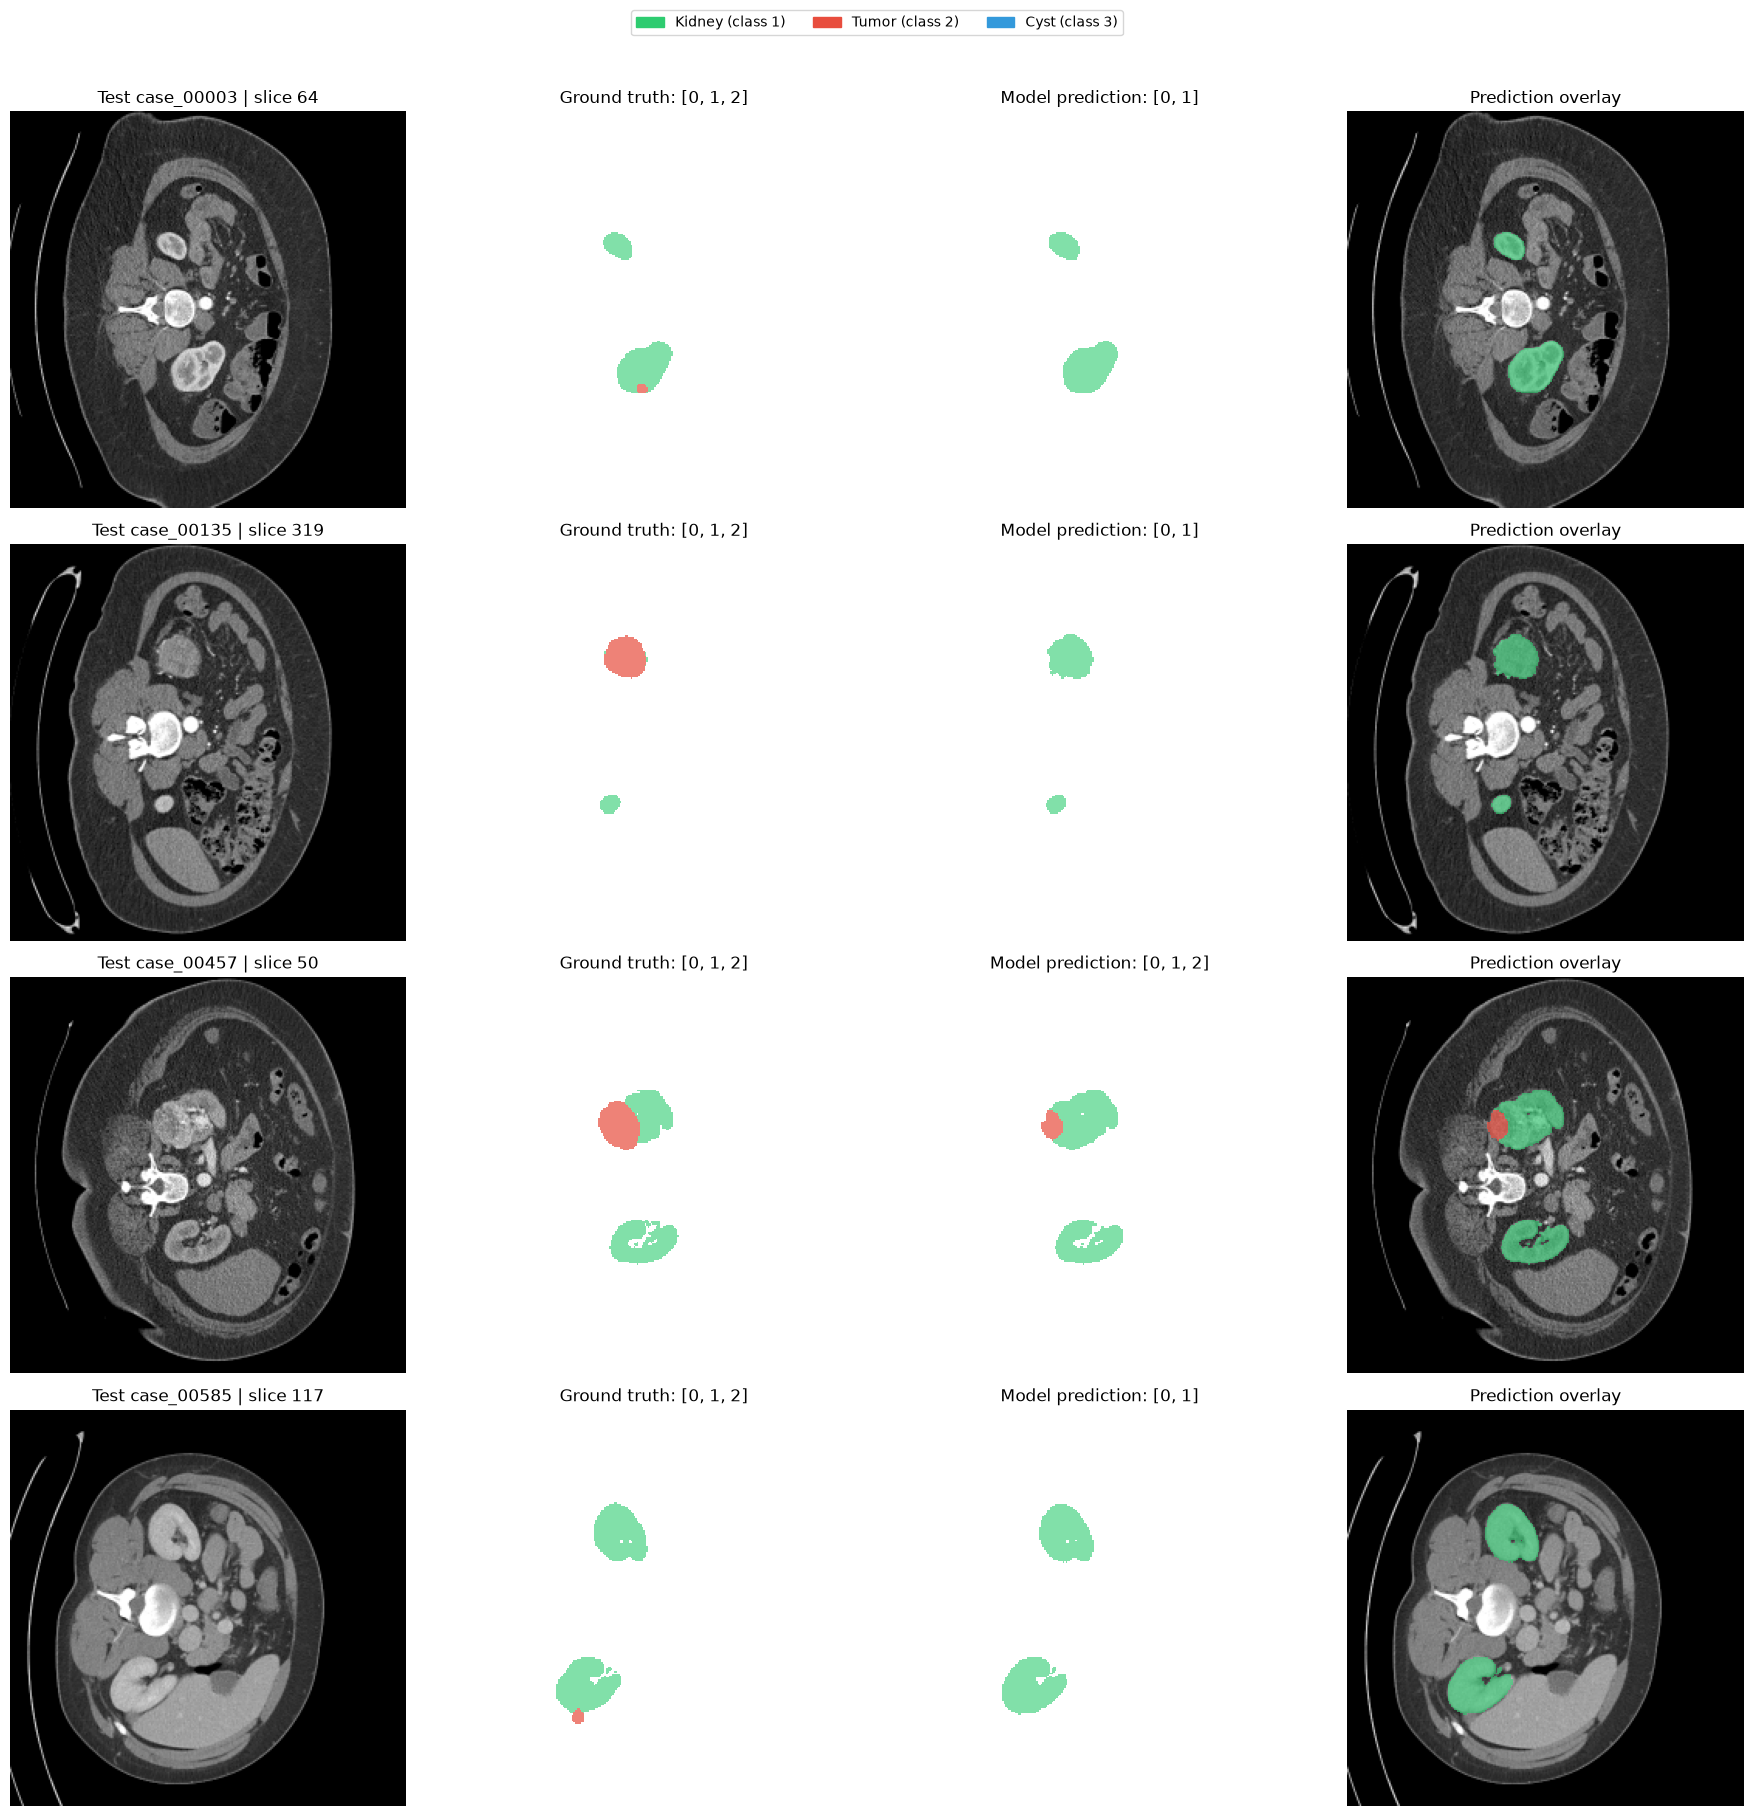

Qualitative audit saved to: D:\Documents\Project\Sem-Project-1\notebookV3\figures\varun_best_unet_test_audit.png


In [53]:
# ============================================================
# 11–12. HELD-OUT TEST EVALUATION & QUALITATIVE AUDIT
# Prerequisite: run the imports and the UNet/DoubleConv definition cells above.
# This evaluates notebookV3/varun_best_unet.pth on test_slices.csv only.
# ============================================================
import time
from pathlib import Path
from typing import Any, Dict

import cv2
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
from tqdm.auto import tqdm
import pandas as pd

# 1. Held-out test data and evaluation loader (same 256x256 preprocessing as training)
DATA_ROOT = Path("D:/archive")
IMAGE_DIR, MASK_DIR = DATA_ROOT / "images", DATA_ROOT / "masks"
TEST_CSV = DATA_ROOT / "splits" / "test_slices.csv"
IMAGE_SIZE, NUM_CLASSES, TEST_BATCH_SIZE = 256, 4, 8
CLASS_NAMES = ["Background", "Kidney", "Tumor", "Cyst"]

assert TEST_CSV.exists(), f"Missing test split: {TEST_CSV}"
test_df = pd.read_csv(TEST_CSV).reset_index(drop=True)
print(f"Held-out test slices: {len(test_df):,} across {test_df['case'].nunique()} cases")

class FastTestDataset(Dataset):
    def __init__(self, dataframe, image_dir, mask_dir, size=256):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir, self.mask_dir, self.size = Path(image_dir), Path(mask_dir), size

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        filename = self.df.iloc[idx]['filename']
        image = np.array(Image.open(self.image_dir / filename))
        mask = np.array(Image.open(self.mask_dir / filename))
        image = cv2.resize(image, (self.size, self.size), interpolation=cv2.INTER_AREA)
        mask = cv2.resize(mask, (self.size, self.size), interpolation=cv2.INTER_NEAREST)
        image = torch.from_numpy(image.astype(np.float32) / 65535.0).unsqueeze(0)
        return image, torch.from_numpy(mask.astype(np.int64)), idx

test_loader = DataLoader(
    FastTestDataset(test_df, IMAGE_DIR, MASK_DIR, IMAGE_SIZE),
    batch_size=TEST_BATCH_SIZE, shuffle=False, num_workers=0,
    pin_memory=(device.type == 'cuda'), drop_last=False,
)

# 2. Load the exact best U-Net checkpoint
checkpoint_candidates = [Path('varun_best_unet.pth'), Path('notebookV3/varun_best_unet.pth')]
BEST_CKPT = next((p for p in checkpoint_candidates if p.exists()), None)
assert BEST_CKPT is not None, 'varun_best_unet.pth was not found in the notebook or project directory.'

test_model = UNet(in_channels=1, num_classes=NUM_CLASSES).to(device)
checkpoint = torch.load(BEST_CKPT, map_location=device, weights_only=False)
state_dict = checkpoint.get('model_state_dict', checkpoint) if isinstance(checkpoint, dict) else checkpoint
test_model.load_state_dict(state_dict)
test_model.eval()
print(f"Loaded checkpoint: {BEST_CKPT.resolve()}")
if isinstance(checkpoint, dict):
    print(f"Saved epoch: {checkpoint.get('epoch', 'unknown')} | best validation Dice: {checkpoint.get('best_val_dice', float('nan')):.4f}")

# 3. Cohort-level pixel metrics: rows=ground truth, columns=prediction
class ComprehensiveMetricsEngine:
    def __init__(self, class_names, smooth=1e-6):
        self.class_names, self.num_classes, self.smooth = class_names, len(class_names), smooth
        self.intersection = np.zeros(self.num_classes, dtype=np.float64)
        self.pred_sum = np.zeros(self.num_classes, dtype=np.float64)
        self.target_sum = np.zeros(self.num_classes, dtype=np.float64)
        self.confusion_matrix = np.zeros((self.num_classes, self.num_classes), dtype=np.int64)

    def update(self, preds, targets):
        p, t = preds.detach().cpu().numpy().astype(np.int64), targets.detach().cpu().numpy().astype(np.int64)
        counts = np.bincount(self.num_classes * t.ravel() + p.ravel(), minlength=self.num_classes ** 2)
        self.confusion_matrix += counts.reshape(self.num_classes, self.num_classes)
        for c in range(self.num_classes):
            p_c, t_c = p == c, t == c
            self.intersection[c] += np.logical_and(p_c, t_c).sum()
            self.pred_sum[c] += p_c.sum()
            self.target_sum[c] += t_c.sum()

    def compute(self) -> Dict[str, Any]:
        results, dice_scores, iou_scores = {}, [], []
        for c, name in enumerate(self.class_names):
            inter, pred_n, target_n = self.intersection[c], self.pred_sum[c], self.target_sum[c]
            dice = (2 * inter + self.smooth) / (pred_n + target_n + self.smooth)
            iou = (inter + self.smooth) / (pred_n + target_n - inter + self.smooth)
            precision = (inter + self.smooth) / (pred_n + self.smooth)
            recall = (inter + self.smooth) / (target_n + self.smooth)
            results.update({f'Dice_{name}': float(dice), f'IoU_{name}': float(iou),
                            f'Precision_{name}': float(precision), f'Recall_{name}': float(recall)})
            dice_scores.append(dice); iou_scores.append(iou)
        results['Foreground_Macro_Dice'] = float(np.mean(dice_scores[1:]))
        results['Foreground_Mean_IoU'] = float(np.mean(iou_scores[1:]))
        results['Overall_Pixel_Accuracy'] = float(np.trace(self.confusion_matrix) / self.confusion_matrix.sum())
        return results

# 4. Run inference. Set EVAL_MAX_BATCHES=100 for a quick smoke test, then use None for final results.
EVAL_MAX_BATCHES = None
metrics, lesion_indices, processed_slices = ComprehensiveMetricsEngine(CLASS_NAMES), [], 0
started = time.time()

with torch.inference_mode():
    for batch_idx, (images, masks, indices) in enumerate(tqdm(test_loader, desc='Testing held-out split', unit='batch')):
        if EVAL_MAX_BATCHES is not None and batch_idx >= EVAL_MAX_BATCHES:
            break
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, dtype=torch.long, non_blocking=True)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            predictions = test_model(images).argmax(dim=1)
        metrics.update(predictions, masks)
        processed_slices += images.shape[0]
        lesion_in_slice = ((masks == 2) | (masks == 3)).flatten(1).any(dim=1).cpu().numpy()
        lesion_indices.extend(indices[lesion_in_slice].tolist())

duration, test_res = time.time() - started, metrics.compute()
print('\n' + '=' * 78)
print('              HELD-OUT TEST SET EVALUATION REPORT (varun_best_unet)')
print('=' * 78)
print(f'Test slices evaluated : {processed_slices:,}')
print(f'Evaluation time       : {duration:.2f} s ({duration / max(processed_slices, 1):.4f} s/slice)')
print(f"Overall pixel accuracy: {test_res['Overall_Pixel_Accuracy'] * 100:.2f}%\n")
print(f"{'Class':<14} | {'Dice':<9} | {'IoU':<9} | {'Precision':<9} | {'Recall':<9}")
print('-' * 62)
for name in CLASS_NAMES:
    print(f"{name:<14} | {test_res[f'Dice_{name}']:.4f}    | {test_res[f'IoU_{name}']:.4f}    | {test_res[f'Precision_{name}']:.4f}    | {test_res[f'Recall_{name}']:.4f}")
print('-' * 62)
print(f"Foreground macro Dice (Kidney, Tumor, Cyst): {test_res['Foreground_Macro_Dice']:.4f}")
print(f"Foreground mean IoU: {test_res['Foreground_Mean_IoU']:.4f}")

# 5. Qualitative audit from lesion-containing slices encountered above
assert lesion_indices, 'No tumor/cyst slices were found in the evaluated portion of the test split.'
sample_positions = np.linspace(0, len(lesion_indices) - 1, min(4, len(lesion_indices)), dtype=int)
audit_indices = [lesion_indices[i] for i in sample_positions]
seg_cmap = ListedColormap([(0, 0, 0, 0), (0.18, 0.80, 0.44, 0.60),
                           (0.91, 0.30, 0.24, 0.70), (0.20, 0.60, 0.86, 0.70)])
legend_patches = [mpatches.Patch(color=c, label=l) for c, l in [
    ((0.18, 0.80, 0.44), 'Kidney (class 1)'), ((0.91, 0.30, 0.24), 'Tumor (class 2)'),
    ((0.20, 0.60, 0.86), 'Cyst (class 3)')]]
fig, axes = plt.subplots(len(audit_indices), 4, figsize=(18, 4.5 * len(audit_indices)), squeeze=False)

with torch.inference_mode():
    for row_i, dataset_idx in enumerate(audit_indices):
        row = test_df.iloc[dataset_idx]
        image = np.array(Image.open(IMAGE_DIR / row['filename']))
        target = np.array(Image.open(MASK_DIR / row['filename']))
        image = cv2.resize(image, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_AREA).astype(np.float32) / 65535.0
        target = cv2.resize(target, (IMAGE_SIZE, IMAGE_SIZE), interpolation=cv2.INTER_NEAREST).astype(np.int64)
        inp = torch.from_numpy(image).unsqueeze(0).unsqueeze(0).to(device)
        with torch.amp.autocast(device_type=device.type, enabled=(device.type == 'cuda')):
            prediction = test_model(inp).argmax(dim=1).squeeze(0).cpu().numpy()
        panels = axes[row_i]
        panels[0].imshow(image, cmap='gray', vmin=0, vmax=1)
        panels[0].set_title(f"Test {row['case']} | slice {row['slice_idx']}")
        panels[1].imshow(target, cmap=seg_cmap, vmin=0, vmax=3, interpolation='nearest')
        panels[1].set_title(f"Ground truth: {np.unique(target).tolist()}")
        panels[2].imshow(prediction, cmap=seg_cmap, vmin=0, vmax=3, interpolation='nearest')
        panels[2].set_title(f"Model prediction: {np.unique(prediction).tolist()}")
        panels[3].imshow(image, cmap='gray', vmin=0, vmax=1)
        panels[3].imshow(prediction, cmap=seg_cmap, vmin=0, vmax=3, interpolation='nearest')
        panels[3].set_title('Prediction overlay')
        for ax in panels: ax.axis('off')

fig.legend(handles=legend_patches, loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.01))
plt.tight_layout(rect=[0, 0, 1, 0.97])
output_fig_path = Path('figures') / 'varun_best_unet_test_audit.png'
output_fig_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Qualitative audit saved to: {output_fig_path.resolve()}")
